# Projeto Forecast — 04. Gráficos

Visualiza o histórico (1970–2022) e as previsões geradas no `03_forecast.ipynb`. As figuras também são salvas em `figuras/` para uso no README.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

DATA = Path('data')
FIG = Path('figuras')
FIG.mkdir(exist_ok=True)

limpo = pd.read_csv(DATA / 'world_population_limpo.csv').set_index('pais')
anual = pd.read_csv(DATA / 'forecast_anual_2022_2027.csv').set_index('pais')
forecast = pd.read_csv(DATA / 'forecast_populacao.csv').set_index('pais')

ANOS_HIST = [1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022]
ANOS_PREV = [2022, 2023, 2024, 2025, 2026, 2027, 2030]

hist = limpo[[f'pop_{a}' for a in ANOS_HIST]].set_axis(ANOS_HIST, axis=1)
prev = anual[[f'pop_{a}' for a in ANOS_PREV[:-1]]].set_axis(ANOS_PREV[:-1], axis=1)
prev[2030] = forecast['pop_2030']

## Estilo

Paleta categórica validada para daltonismo (ordem fixa: a cor segue a entidade, não a posição), linhas finas, grade discreta atrás dos dados e textos sempre em tons de cinza; a cor fica só nas marcas. Números no padrão brasileiro.

In [2]:
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
POSITIVO, NEGATIVO = '#2a78d6', '#e34948'
TEXTO, TEXTO_2, GRADE, FUNDO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'savefig.facecolor': FUNDO,
    'figure.dpi': 110, 'font.size': 10,
    'text.color': TEXTO, 'axes.labelcolor': TEXTO_2,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.edgecolor': GRADE, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRADE, 'grid.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'lines.linewidth': 2, 'legend.frameon': False,
})

def br(valor, casas=1):
    """Formata número no padrão brasileiro (1.234,5)."""
    return f'{valor:,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def titulo(ax, texto, subtitulo):
    ax.set_title(texto, pad=24)
    ax.text(0, 1.02, subtitulo, transform=ax.transAxes, color=TEXTO_2, fontsize=9)

def marca_previsao(ax):
    """Sombreia o período previsto e escreve 'previsão' no rodapé da faixa."""
    ax.axvspan(2022, 2030, color=GRADE, alpha=0.35, lw=0)
    ax.text(2026, 0.03, 'previsão', transform=ax.get_xaxis_transform(),
            color=TEXTO_2, ha='center', fontsize=9)

def afasta_rotulos(valores, distancia):
    """Ajusta as posições verticais dos rótulos para manter uma distância mínima entre eles."""
    pos, anterior = {}, None
    for chave in sorted(valores, key=valores.get):
        y = valores[chave] if anterior is None else max(valores[chave], anterior + distancia)
        pos[chave] = anterior = y
    return pos

## 1. População mundial: histórico e previsão

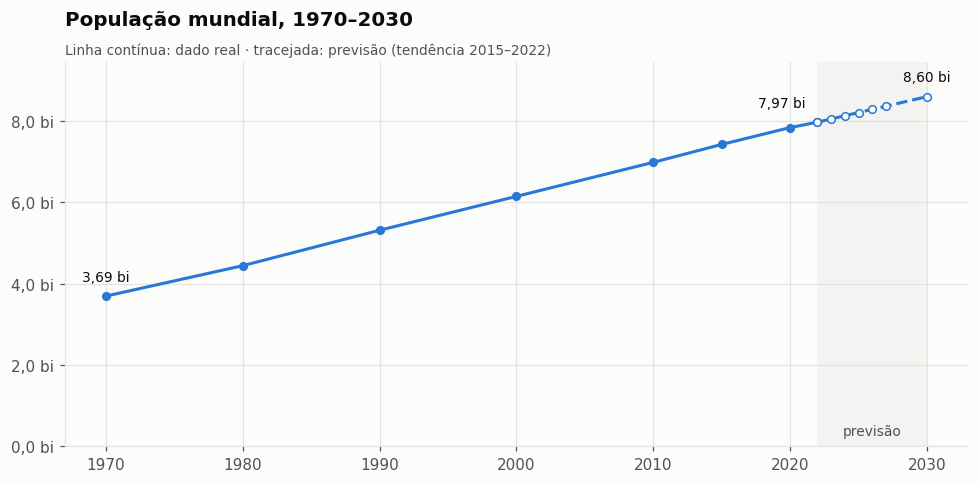

In [3]:
mundo_hist, mundo_prev = hist.sum(), prev.sum()

fig, ax = plt.subplots(figsize=(9, 4.5))
marca_previsao(ax)
ax.plot(mundo_hist.index, mundo_hist, color=SERIES[0], marker='o', ms=5)
ax.plot(mundo_prev.index, mundo_prev, color=SERIES[0], ls='--', marker='o', ms=5, mfc=FUNDO)

for ano, valor in [(1970, mundo_hist[1970]), (2022, mundo_hist[2022]), (2030, mundo_prev[2030])]:
    ax.annotate(f'{br(valor / 1e9, 2)} bi', (ano, valor), xytext=(-8 if ano == 2022 else 0, 10),
                textcoords='offset points', ha='right' if ano == 2022 else 'center',
                color=TEXTO, fontsize=9)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{br(v / 1e9)} bi'))
ax.set_ylim(0, mundo_prev.max() * 1.1)
titulo(ax, 'População mundial, 1970–2030',
       'Linha contínua: dado real · tracejada: previsão (tendência 2015–2022)')
fig.tight_layout()
fig.savefig(FIG / '01_mundo.png')
plt.show()

## 2. Os 5 países mais populosos

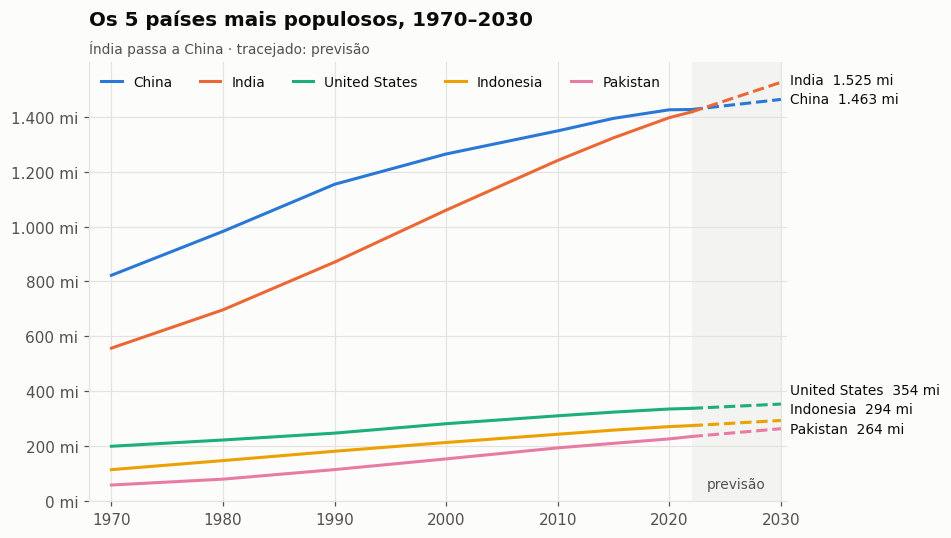

In [4]:
top5 = hist[2022].nlargest(5).index

fig, ax = plt.subplots(figsize=(9, 5))
marca_previsao(ax)
for cor, pais in zip(SERIES, top5):
    ax.plot(hist.columns, hist.loc[pais], color=cor, label=pais)
    ax.plot(prev.columns, prev.loc[pais], color=cor, ls='--')

posicoes = afasta_rotulos(prev.loc[top5, 2030].to_dict(), distancia=70e6)
for pais, y in posicoes.items():
    ax.annotate(f'{pais}  {br(prev.loc[pais, 2030] / 1e6, 0)} mi', (2030, y), xytext=(6, 0),
                textcoords='offset points', va='center', color=TEXTO, fontsize=9,
                annotation_clip=False)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{br(v / 1e6, 0)} mi'))
ax.set_ylim(bottom=0)
ax.set_xlim(1968, 2030.5)
ax.legend(loc='upper left', ncols=5, fontsize=9, handlelength=1.5)
titulo(ax, 'Os 5 países mais populosos, 1970–2030', 'Índia passa a China · tracejado: previsão')
fig.tight_layout()
fig.subplots_adjust(right=0.80)
fig.savefig(FIG / '02_top5_paises.png')
plt.show()

## 3. Crescimento anual previsto por continente (2023–2027)

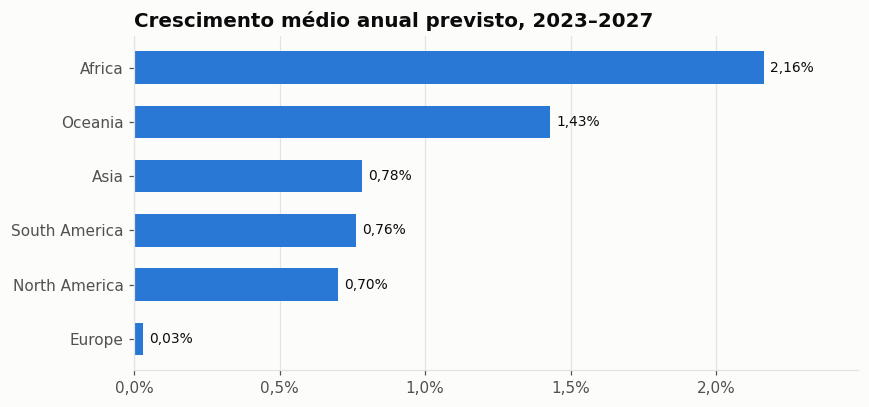

In [5]:
cont = anual.groupby('continente')[[f'pop_{a}' for a in range(2022, 2028)]].sum()
cresc_medio = ((cont['pop_2027'] / cont['pop_2022']) ** (1 / 5) - 1) * 100
cresc_medio = cresc_medio.sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
barras = ax.barh(cresc_medio.index, cresc_medio, color=SERIES[0], height=0.6)
ax.bar_label(barras, labels=[f'{br(v, 2)}%' for v in cresc_medio], padding=4, color=TEXTO, fontsize=9)
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{br(v)}%'))
ax.set_xlim(0, cresc_medio.max() * 1.15)
ax.set_title('Crescimento médio anual previsto, 2023–2027')
fig.tight_layout()
fig.savefig(FIG / '03_crescimento_continentes.png')
plt.show()

## 4. Quem mais cresce e quem mais encolhe até 2030

Só países com mais de 1 milhão de habitantes, para não destacar territórios minúsculos.

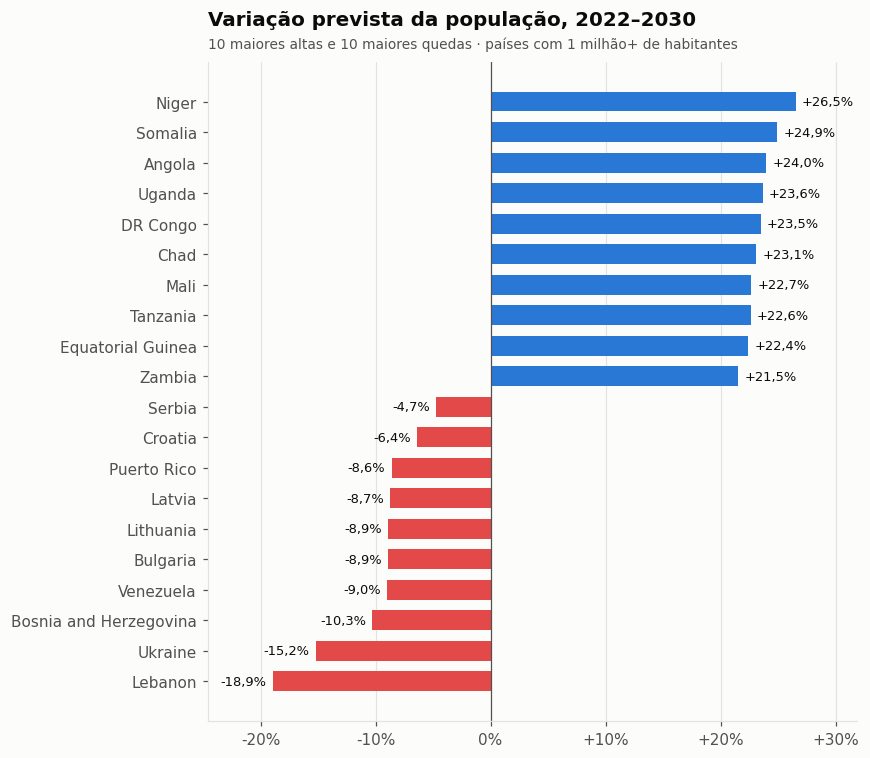

In [6]:
grandes = forecast[forecast['pop_2022'] >= 1_000_000]['var_2022_2030_%']
extremos = pd.concat([grandes.nsmallest(10), grandes.nlargest(10)]).sort_values()
cores = [POSITIVO if v > 0 else NEGATIVO for v in extremos]

fig, ax = plt.subplots(figsize=(8, 7))
barras = ax.barh(extremos.index, extremos, color=cores, height=0.65)
ax.bar_label(barras, labels=[('+' if v > 0 else '') + f'{br(v)}%' for v in extremos],
             padding=4, color=TEXTO, fontsize=8.5)
ax.axvline(0, color=TEXTO_2, lw=0.8)
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:+.0f}%' if v else '0%'))
ax.set_xlim(extremos.min() * 1.3, extremos.max() * 1.2)
titulo(ax, 'Variação prevista da população, 2022–2030',
       '10 maiores altas e 10 maiores quedas · países com 1 milhão+ de habitantes')
fig.tight_layout()
fig.savefig(FIG / '04_maiores_variacoes.png')
plt.show()

## Leitura dos gráficos

- O mundo segue crescendo cerca de 0,95% ao ano, mas o ritmo vem caindo desde 1970.
- A Índia ultrapassa a China; Nigéria e Paquistão são os que mais crescem entre os grandes.
- A África concentra o crescimento (~2,2% ao ano); a Europa fica praticamente parada.
- As maiores quedas vêm de países com guerra ou emigração forte (Ucrânia, Líbano), exatamente onde a previsão por tendência é menos confiável.